# Doubly Robust Results Analysis

This notebook analyzes the updated `wu2024_article` results with doubly robust methods included. It keeps the metric figures aligned with notebook `04_synthetic_results_analysis.ipynb`, shows all models together for metrics and global curves, and restricts patient-surface figures to DR methods only because these methods do not have decision-aware (DA) weighting variants.

In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "src").exists():
    for parent in Path.cwd().parents:
        if (parent / "src").exists():
            PROJECT_ROOT = parent
            break
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.analysis.results_analysis import (
    available_metrics,
    export_analysis_tables,
    load_global_curves,
    load_patient_curves,
    load_patient_metadata,
    load_results_metrics,
    make_publication_table,
    metric_spec_available,
    non_oracle_methods,
    plot_global_curves,
    plot_patient_surface_from_table,
    plot_patient_surface_gallery_from_table,
    run_statistical_tests,
    save_figure,
    set_plot_theme,
    statistical_test_table,
    summarize_metric_ci,
)

set_plot_theme(style="whitegrid", context="notebook", font_scale=1.0)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 260)
pd.set_option("display.expand_frame_repr", False)

plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["savefig.facecolor"] = "white"
plt.rcParams["savefig.edgecolor"] = "white"

PROJECT_ROOT

WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr')

## Editable Configuration

This notebook is self-contained. Method constants and grouped DA barplot helpers are defined here directly so the notebook does not depend on other notebooks.

In [2]:
RESULTS_DIR = PROJECT_ROOT / "results" / "wu2024_article"

# Set to None to analyze every seed available in results/wu2024_article.
SEEDS_TO_ANALYZE = None
if SEEDS_TO_ANALYZE is None:
    SEED_LABEL = "all_seeds"
else:
    SEED_LABEL = f"seeds_{min(SEEDS_TO_ANALYZE)}_{max(SEEDS_TO_ANALYZE)}"

ANALYSIS_DIR = RESULTS_DIR / "analysis" / "07_doubly_robust_results" / SEED_LABEL
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

EXCLUDED_METHODS = {"NMMR", "Weighted NMMR"}

DEFAULT_SPLIT = "test"
ALPHA = 0.05
CONFIDENCE = 0.95

RMSE_YMAX_EXCLUDE_FAMILIES = ["NMMR-U", "Weighted NMMR-U"]
RMSE_YMAX_MARGIN_RATIO = 0.08

RESULTS_DIR, ANALYSIS_DIR

(WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr/results/wu2024_article'),
 WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr/results/wu2024_article/analysis/07_doubly_robust_results/all_seeds'))

In [3]:
METHOD_ORDER = [
    "PMMR",
    "Weighted PMMR",
    "NMMR-U",
    "Weighted NMMR-U",
    "NMMR-V",
    "Weighted NMMR-V",
    "NMMR",
    "Weighted NMMR",
    "KPV",
    "Weighted KPV",
    "DFPV",
    "Weighted DFPV",
    "DR-KPV",
    "DR-PMMR conditional",
    "DR-PMMR marginal",
    "S-Learner",
    "Naive OOSR",
    "Oracle S-Learner",
    "Oracle Naive OOSR",
]

METHOD_LABELS = {
    "Weighted PMMR": "DA-PMMR",
    "Weighted NMMR-U": "DA-NMMR-U",
    "Weighted NMMR-V": "DA-NMMR-V",
    "NMMR": "NMMR",
    "Weighted NMMR": "DA-NMMR",
    "Weighted KPV": "DA-KPV",
    "Weighted DFPV": "DA-DFPV",
    "DR-PMMR conditional": "DR-PMMR",
    "DR-PMMR marginal": "DR-PMMR marg.",
    "Naive OOSR": "W-S-Learner",
    "Oracle S-Learner": "Oracle",
    "Oracle Naive OOSR": "OOSR oracle",
    "ground_truth_oracle_conditioned": "Ground truth",
    "causal_marginal": "Causal marginal",
    "proxy_conditioned": "Proxy-conditioned",
    "structure_term": "Structure term",
    "ground_truth_causal": r"$E[Y(a)|x]$",
    "associational": r"$E[Y|x,a]$",
    "oracle_conditioned": "Oracle-conditioned",
}

METHOD_COLORS = {
    "PMMR": "#1f77b4",
    "Weighted PMMR": "#17becf",
    "NMMR-U": "#ff7f0e",
    "Weighted NMMR-U": "#d62728",
    "NMMR-V": "#e377c2",
    "Weighted NMMR-V": "#9467bd",
    "NMMR": "#9edae5",
    "Weighted NMMR": "#8c564b",
    "KPV": "#2ca02c",
    "Weighted KPV": "#8c564b",
    "DFPV": "#bcbd22",
    "Weighted DFPV": "#F54927",
    "DR-KPV": "#4d4d4d",
    "DR-PMMR conditional": "#6a3d9a",
    "DR-PMMR marginal": "#b15928",
    "S-Learner": "#7f7f7f",
    "Naive OOSR": "#8c564b",
    "Oracle S-Learner": "#5254a3",
    "Oracle Naive OOSR": "#8ca252",
}

METHOD_LINESTYLES = {
    "PMMR": "-",
    "Weighted PMMR": "--",
    "NMMR-U": "-",
    "Weighted NMMR-U": "--",
    "NMMR-V": "-",
    "Weighted NMMR-V": "--",
    "NMMR": "-.",
    "Weighted NMMR": ":",
    "KPV": "-",
    "Weighted KPV": ":",
    "DFPV": "-.",
    "Weighted DFPV": "--",
    "DR-KPV": "--",
    "DR-PMMR conditional": "-.",
    "DR-PMMR marginal": ":",
    "S-Learner": "-",
    "Naive OOSR": "--",
    "Oracle S-Learner": "-.",
    "Oracle Naive OOSR": ":",
}

METRICS_TO_PLOT = [
    "val_regret",
    "factual_mean_rmse",
    "global_rmse",
    "local_rmse",
    "mean_curve_rmse",
    "mean_curve_argmax_abs_error",
    "regret_causal_marginal",
    "policy_mse_causal_marginal",
    "policy_value_causal_marginal",
]

METRIC_LABELS = {
    "val_regret": "Validation regret",
    "factual_mean_rmse": "Factual RMSE",
    "global_rmse": "Counterfactual RMSE",
    "local_rmse": "Local RMSE",
    "mean_curve_rmse": "Mean curve RMSE",
    "mean_curve_argmax_abs_error": "Argmax absolute error",
    "regret_causal_marginal": "Policy regret",
    "policy_mse_causal_marginal": "Policy MSE",
    "policy_value_causal_marginal": "Policy value",
}

METRIC_DIRECTIONS = {
    "policy_value_causal_marginal": True,
    "policy_value_oracle": True,
    "policy_value_structural": True,
}

PROXIMAL_DA_BASE_METHODS = [
    method for method in METHOD_ORDER
    if not str(method).startswith("Weighted ") and f"Weighted {method}" in set(METHOD_ORDER)
]
DA_PATTERN_MAP = {"standard": None, "DA": "//..."}
METHOD_FAMILY_MODE_OVERRIDES = {
    "S-Learner": ("S-Learner", "standard"),
    "Naive OOSR": ("Naive OOSR", "standard"),
    "DA-S-Learner": ("S-Learner", "DA"),
}

def ordered_existing_methods(available_methods):
    available = [str(method) for method in available_methods if pd.notna(method)]
    ordered = [method for method in METHOD_ORDER if method in set(available)]
    ordered += sorted(method for method in available if method not in set(ordered))
    return ordered

def _split_family_mode(method_name: str) -> tuple[str, str]:
    method_name = str(method_name)
    if method_name in METHOD_FAMILY_MODE_OVERRIDES:
        family, mode = METHOD_FAMILY_MODE_OVERRIDES[method_name]
        return str(family), str(mode)
    if method_name.startswith("Weighted "):
        base = method_name[len("Weighted "):]
        if base in PROXIMAL_DA_BASE_METHODS:
            return base, "DA"
    return method_name, "standard"

def _ordered_families_from_methods(observed_families):
    observed = {str(family) for family in observed_families}
    ordered = []
    for method in METHOD_ORDER:
        family, _ = _split_family_mode(str(method))
        if family in observed and family not in ordered:
            ordered.append(family)
    ordered.extend(sorted(family for family in observed if family not in set(ordered)))
    return ordered

def _family_color_map(families):
    out = {}
    for family in families:
        if family in METHOD_COLORS:
            out[family] = METHOD_COLORS[family]
        elif f"Weighted {family}" in METHOD_COLORS:
            out[family] = METHOD_COLORS[f"Weighted {family}"]
        else:
            out[family] = "tab:blue"
    return out

def _build_metric_plot_df(metrics_df, summary_df, metrics):
    rows = []
    source_map = (
        summary_df.loc[summary_df["metric"].isin(metrics), ["metric", "source_split", "source_metric"]]
        .drop_duplicates()
    )
    for _, source_row in source_map.iterrows():
        metric = str(source_row["metric"])
        split_name = str(source_row["source_split"])
        source_metric = str(source_row["source_metric"])
        if source_metric not in metrics_df.columns:
            continue
        frame = metrics_df.copy()
        if "split" in frame.columns:
            frame = frame[frame["split"].astype(str) == split_name]
        if frame.empty:
            continue
        tmp = frame[["method", source_metric]].copy()
        tmp["value"] = pd.to_numeric(tmp[source_metric], errors="coerce")
        tmp = tmp[tmp["value"].notna()].copy()
        if tmp.empty:
            continue
        tmp["metric"] = metric
        rows.append(tmp[["method", "metric", "value"]])
    if not rows:
        return pd.DataFrame(columns=["method", "metric", "value", "family", "mode"])
    plot_df = pd.concat(rows, ignore_index=True)
    family_mode = plot_df["method"].astype(str).map(_split_family_mode)
    plot_df["family"] = [family for family, _ in family_mode]
    plot_df["mode"] = [mode for _, mode in family_mode]
    return plot_df

def _rmse_axis_upper_limit(metric_name: str, metric_df: pd.DataFrame):
    metric_name = str(metric_name).lower()
    if "rmse" not in metric_name:
        return None
    values = metric_df.copy()
    if "family" in values.columns:
        values = values[~values["family"].astype(str).isin(set(RMSE_YMAX_EXCLUDE_FAMILIES))]
    series = pd.to_numeric(values.get("value"), errors="coerce")
    series = series[series.notna()]
    if series.empty:
        series = pd.to_numeric(metric_df.get("value"), errors="coerce")
        series = series[series.notna()]
    if series.empty:
        return None
    ymax = float(series.max())
    if ymax <= 0:
        return None
    return ymax * (1.0 + float(RMSE_YMAX_MARGIN_RATIO))

def plot_method_metrics_ci_grid_da_grouped(
    metrics_df,
    summary_df,
    metrics,
    *,
    metric_labels=None,
    ncols=3,
    figsize_per_panel=(5.4, 4.2),
    pattern_map=None,
    confidence=0.95,
    n_boot=2000,
    bootstrap_seed=13,
    title="Method metrics with bootstrap confidence intervals",
):
    import math
    import numpy as np
    import seaborn as sns
    import matplotlib.pyplot as plt
    from matplotlib.patches import Patch

    pattern_map = pattern_map or DA_PATTERN_MAP
    plot_df = _build_metric_plot_df(metrics_df, summary_df, metrics)
    if plot_df.empty:
        raise ValueError("No metric rows available to draw the metric grid.")
    available_metrics_set = set(plot_df["metric"].astype(str))
    metrics = [metric for metric in metrics if metric in available_metrics_set]
    if not metrics:
        raise ValueError("None of the requested metrics are present in the plot table.")
    nrows = int(math.ceil(len(metrics) / ncols))
    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(figsize_per_panel[0] * ncols, figsize_per_panel[1] * nrows),
        squeeze=False,
    )
    confidence_pct = int(round(float(confidence) * 100))
    mode_order = ["standard", "DA"]
    mode_label_map = {"standard": "Standard", "DA": "Decision-Aware"}
    for ax, metric in zip(axes.ravel(), metrics):
        metric_df = plot_df[plot_df["metric"].astype(str) == str(metric)].copy()
        if metric_df.empty:
            ax.axis("off")
            continue
        family_order = _ordered_families_from_methods(metric_df["family"].dropna().unique())
        color_map = _family_color_map(family_order)
        sns.barplot(
            data=metric_df,
            x="family",
            y="value",
            hue="mode",
            order=family_order,
            hue_order=mode_order,
            estimator=np.mean,
            errorbar=("ci", confidence_pct),
            n_boot=int(n_boot),
            seed=int(bootstrap_seed),
            dodge=True,
            edgecolor="black",
            linewidth=0.8,
            alpha=0.9,
            ax=ax,
        )
        tick_positions = np.asarray(ax.get_xticks(), dtype=float)
        present_modes = [mode for mode in mode_order if mode in set(metric_df["mode"].astype(str))]
        one_mode_only = len(present_modes) == 1
        single_mode = present_modes[0] if one_mode_only else None
        for patch in ax.patches:
            center_x = patch.get_x() + patch.get_width() / 2.0
            family_idx = int(np.argmin(np.abs(tick_positions - center_x)))
            family = family_order[family_idx]
            if one_mode_only:
                mode = single_mode
            else:
                mode = "standard" if center_x <= tick_positions[family_idx] else "DA"
            patch.set_facecolor(color_map[family])
            hatch = pattern_map.get(mode)
            if hatch:
                patch.set_hatch(hatch)
        tick_labels = [METHOD_LABELS.get(family, family) for family in family_order]
        ax.set_xticks(tick_positions)
        ax.set_xticklabels(tick_labels, rotation=30, ha="right")
        rmse_ymax = _rmse_axis_upper_limit(metric, metric_df)
        if rmse_ymax is not None:
            ax.set_ylim(top=rmse_ymax)
        metric_label = metric_labels.get(metric, metric.replace("_", " ")) if metric_labels else metric.replace("_", " ")
        ax.set_title(metric_label)
        ax.set_ylabel(metric_label)
        ax.set_xlabel("")
        ax.grid(axis="y", alpha=0.25)
        legend = ax.get_legend()
        if legend is not None:
            legend.remove()
    for ax in axes.ravel()[len(metrics):]:
        ax.axis("off")
    common_handles = [
        Patch(facecolor="lightgray", edgecolor="black", hatch=pattern_map.get(mode) or "", label=mode_label_map[mode])
        for mode in mode_order
        if mode in set(plot_df["mode"].astype(str))
    ]
    if common_handles:
        fig.legend(
            handles=common_handles,
            loc="upper center",
            bbox_to_anchor=(0.5, 1.01),
            ncol=max(1, len(common_handles)),
            frameon=False,
            title=None,
        )
    fig.suptitle(title, y=1.045)
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    return fig

METHOD_ORDER

['PMMR',
 'Weighted PMMR',
 'NMMR-U',
 'Weighted NMMR-U',
 'NMMR-V',
 'Weighted NMMR-V',
 'NMMR',
 'Weighted NMMR',
 'KPV',
 'Weighted KPV',
 'DFPV',
 'Weighted DFPV',
 'DR-KPV',
 'DR-PMMR conditional',
 'DR-PMMR marginal',
 'S-Learner',
 'Naive OOSR',
 'Oracle S-Learner',
 'Oracle Naive OOSR']

## Load Result Tables

All downstream summaries and figures use the selected seeds and the methods listed in `METHOD_ORDER`, excluding NMMR and Weighted NMMR.

In [4]:
metrics_df = load_results_metrics(RESULTS_DIR)
if SEEDS_TO_ANALYZE is not None:
    seed_set = {int(seed) for seed in SEEDS_TO_ANALYZE}
    metrics_df = metrics_df[metrics_df["seed"].astype("Int64").isin(seed_set)].copy()

metrics_df = metrics_df[metrics_df["method"].isin(METHOD_ORDER) & ~metrics_df["method"].isin(EXCLUDED_METHODS)].copy()

global_curves_df = load_global_curves(RESULTS_DIR, seeds=SEEDS_TO_ANALYZE)
patient_curves_df = load_patient_curves(RESULTS_DIR, seeds=SEEDS_TO_ANALYZE)
patient_metadata_df = load_patient_metadata(RESULTS_DIR, seeds=SEEDS_TO_ANALYZE)
global_curves_df = global_curves_df[global_curves_df["method"].isin(set(METHOD_ORDER) | {"reference"}) & ~global_curves_df["method"].isin(EXCLUDED_METHODS)].copy()
patient_curves_df = patient_curves_df[patient_curves_df["method"].isin(set(METHOD_ORDER) | {"reference"}) & ~patient_curves_df["method"].isin(EXCLUDED_METHODS)].copy()

selected_seeds = sorted(metrics_df["seed"].dropna().astype(int).unique().tolist())
available_methods = ordered_existing_methods(metrics_df["method"].dropna().unique())
available_surface_methods = ordered_existing_methods(
    patient_curves_df.loc[patient_curves_df["curve_type"] == "prediction", "method"].dropna().unique()
)
dr_surface_methods = [method for method in available_surface_methods if str(method).startswith("DR-")]
dr_prediction_rows = patient_curves_df[
    (patient_curves_df["curve_type"].astype(str) == "prediction")
    & (patient_curves_df["method"].astype(str).str.startswith("DR-"))
].copy()
dr_surface_seeds = sorted(dr_prediction_rows["seed"].dropna().astype(int).unique().tolist())

available_test_metrics = available_metrics(metrics_df, split=DEFAULT_SPLIT)
metrics_to_use = [
    metric for metric in METRICS_TO_PLOT
    if metric_spec_available(metrics_df, metric, split=DEFAULT_SPLIT)
]

print(f"selected seeds: {selected_seeds}")
print(f"available methods ({len(available_methods)}): {available_methods}")
print(f"DR surface methods: {dr_surface_methods}")
print(f"DR surface seeds: {dr_surface_seeds}")
print(f"metrics_to_use: {metrics_to_use}")

display(metrics_df.head())
display(patient_curves_df[["raw_method", "method"]].drop_duplicates().sort_values(["method", "raw_method"]))

selected seeds: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
available methods (15): ['PMMR', 'Weighted PMMR', 'NMMR-U', 'Weighted NMMR-U', 'NMMR-V', 'Weighted NMMR-V', 'KPV', 'Weighted KPV', 'DFPV', 'Weighted DFPV', 'DR-KPV', 'DR-PMMR conditional', 'S-Learner', 'Naive OOSR', 'Oracle S-Learner']
DR surface methods: ['DR-KPV', 'DR-PMMR conditional']
DR surface seeds: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
metrics_to_use: ['val_regret', 'factual_mean_rmse', 'global_rmse', 'local_rmse', 'mean_curve_rmse', 'mean_curve_argmax_abs_error', 'regret_causal_marginal', 'policy_mse_causal_marginal', 'policy_value_causal_marginal']


,dataset,seed,split,model_key,method,run_dir,dr_kap_eta,dr_kap_lambda,dr_kap_lambda2,dr_kap_zeta,dr_kpv_lambda1,dr_kpv_lambda2,dr_lambda_dr,dr_pmmr_lambda,factual_mean_mae,factual_mean_rmse,global_rmse,kpv_lambda1,kpv_lambda2,local_rmse,mean_curve_argmax_abs_error,mean_curve_bias,mean_curve_direct_argmax_abs_error,mean_curve_direct_bias,mean_curve_direct_mae,mean_curve_direct_pred_argmax,mean_curve_direct_rmse,mean_curve_direct_true_argmax,mean_curve_mae,mean_curve_pred_argmax,mean_curve_rmse,mean_curve_true_argmax,observed_rmse,optimal_policy_value,optimal_policy_value_causal_marginal,optimal_policy_value_oracle,optimal_policy_value_structural,policy_mse,policy_mse_causal_marginal,policy_mse_oracle,policy_mse_structural,policy_value,policy_value_causal_marginal,policy_value_oracle,policy_value_structural,pseudo_outcome_iqr,pseudo_outcome_std,regret,regret_causal_marginal,regret_oracle,regret_structural,weight_ess_final,raw_method
0,wu2024_nonadditive,0,test,dfpv,DFPV,results/wu2024_article/runs/seed_0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.264327,2.854306,7.250690,NaN,NaN,1.535057,1.638807,0.678094,0.595930,-0.699940,4.798768,1.314113,5.580340,0.718183,5.948475,2.356990,6.905607,0.718183,3.595098,0.997879,0.997879,1.163254,1.133451,3.560189,3.560189,3.466197,3.467240,-7.937499,-7.937499,-7.594885,-7.579422,NaN,NaN,8.935378,8.935378,8.758139,8.712873,NaN,DFPV
1,wu2024_nonadditive,0,test,kpv,KPV,results/wu2024_article/runs/seed_0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.988493,2.525695,4.226952,0.03,0.001,1.073923,1.638807,1.323591,0.670421,1.243986,3.161422,1.388604,3.946166,0.718183,3.021000,2.356990,3.952257,0.718183,2.752183,0.997879,0.997879,1.163254,1.133451,3.170159,3.170159,3.082504,3.083647,-7.064110,-7.064110,-6.733598,-6.735083,NaN,NaN,8.061989,8.061989,7.896852,7.868534,NaN,KPV
3,wu2024_nonadditive,0,test,oracle_s_learner,Oracle S-Learner,results/wu2024_article/runs/seed_0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.643383,3.416321,1.548938,NaN,NaN,0.690633,0.148982,1.062584,NaN,NaN,NaN,NaN,NaN,NaN,1.062584,0.569201,1.348827,0.718183,0.153208,0.997879,0.997879,1.163254,1.133451,0.015736,0.015736,0.013956,0.013822,0.723243,0.723243,0.900885,0.872709,NaN,NaN,0.274636,0.274636,0.262369,0.260742,NaN,Oracle S-Learner
4,wu2024_nonadditive,0,test,pmmr,PMMR,results/wu2024_article/runs/seed_0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.337792,2.904998,6.807740,NaN,NaN,1.737543,1.415333,0.650628,1.117368,0.202020,5.401281,1.835552,6.109902,0.718183,5.180792,2.133516,5.950400,0.718183,4.438226,0.997879,0.997879,1.163254,1.133451,2.532052,2.532052,2.394069,2.395911,-5.664955,-5.664955,-5.183292,-5.218365,NaN,NaN,6.662834,6.662834,6.346546,6.351816,NaN,PMMR
5,wu2024_nonadditive,0,test,s_learner,S-Learner,results/wu2024_article/runs/seed_0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.763944,NaN,NaN,0.936621,1.638807,-0.164937,NaN,NaN,NaN,NaN,NaN,NaN,4.669827,2.356990,5.525403,0.718183,2.329977,0.997879,0.997879,1.163254,1.133451,3.594284,3.594284,3.500600,3.501743,-8.020447,-8.020447,-7.680204,-7.663907,NaN,NaN,9.018325,9.018325,8.843458,8.797358,NaN,S-Learner


,raw_method,method
306,DFPV,DFPV
535500,DR_KPV,DR-KPV
535551,DR_PMMR_Conditional,DR-PMMR conditional
255,KPV,KPV
357000,NMMR_U,NMMR-U
357051,NMMR_V,NMMR-V
484551,Naive_OOSR,Naive OOSR
510,Oracle_S_Learner,Oracle S-Learner
204,PMMR,PMMR
561,S_Learner,S-Learner


## Metric Tables With Confidence Intervals

In [5]:
summary_df = summarize_metric_ci(
    metrics_df,
    metrics_to_use,
    split=DEFAULT_SPLIT,
    confidence=CONFIDENCE,
)
publication_table = make_publication_table(summary_df, metrics=metrics_to_use)
display(publication_table.reindex(index=[m for m in METHOD_ORDER if m in publication_table.index]))

written_tables = export_analysis_tables(
    ANALYSIS_DIR,
    metric_summary=summary_df,
    publication_table=publication_table,
)
written_tables

metric,val_regret,factual_mean_rmse,global_rmse,local_rmse,mean_curve_rmse,mean_curve_argmax_abs_error,regret_causal_marginal,policy_mse_causal_marginal,policy_value_causal_marginal
method,,,,,,,,,
PMMR,"4.946 [3.867, 6.025]","3.005 [2.934, 3.076]","6.861 [6.615, 7.108]","1.454 [1.352, 1.557]","6.144 [5.822, 6.467]","1.023 [0.761, 1.285]","4.922 [3.806, 6.038]","1.764 [1.262, 2.266]","-3.849 [-4.966, -2.732]"
Weighted PMMR,"4.377 [3.465, 5.288]","3.213 [3.046, 3.381]","6.719 [6.442, 6.997]","2.003 [1.735, 2.271]","5.937 [5.612, 6.263]","0.919 [0.692, 1.145]","4.317 [3.359, 5.274]","1.493 [1.067, 1.920]","-3.244 [-4.207, -2.280]"
NMMR-U,"7.883 [6.906, 8.860]","1400.431 [-878.149, 3679.010]","1524.022 [-892.094, 3940.137]","1371.795 [-908.219, 3651.810]","583.703 [-287.418, 1454.825]","1.631 [1.421, 1.842]","7.938 [6.915, 8.961]","3.114 [2.650, 3.578]","-6.832 [-7.848, -5.817]"
Weighted NMMR-U,"4.984 [3.404, 6.564]","4022.211 [1159.759, 6884.662]","4641.465 [1284.556, 7998.375]","3594.686 [1031.420, 6157.952]","3309.340 [829.680, 5789.000]","1.058 [0.719, 1.396]","4.987 [3.377, 6.597]","1.801 [1.084, 2.518]","-3.882 [-5.496, -2.267]"
NMMR-V,"4.885 [3.423, 6.347]","2.530 [2.460, 2.600]","4.382 [4.236, 4.528]","1.013 [0.938, 1.087]","4.217 [4.062, 4.373]","1.065 [0.820, 1.310]","4.906 [3.417, 6.395]","1.733 [1.054, 2.412]","-3.800 [-5.295, -2.305]"
Weighted NMMR-V,"4.723 [3.126, 6.320]","2.682 [2.511, 2.854]","4.045 [3.641, 4.450]","1.169 [0.994, 1.345]","3.869 [3.425, 4.314]","1.013 [0.747, 1.279]","4.745 [3.117, 6.374]","1.663 [0.923, 2.402]","-3.640 [-5.271, -2.008]"
KPV,"4.867 [4.240, 5.493]","2.606 [2.562, 2.649]","4.244 [4.164, 4.323]","0.922 [0.867, 0.978]","4.031 [3.933, 4.128]","1.073 [0.948, 1.197]","4.883 [4.216, 5.551]","1.717 [1.412, 2.022]","-3.810 [-4.492, -3.129]"
Weighted KPV,"3.302 [2.947, 3.657]","2.823 [2.735, 2.910]","3.969 [3.890, 4.048]","1.123 [1.052, 1.193]","3.635 [3.516, 3.754]","0.745 [0.662, 0.828]","3.311 [2.960, 3.661]","0.999 [0.840, 1.159]","-2.205 [-2.555, -1.855]"
DFPV,"7.524 [6.475, 8.572]","2.908 [2.739, 3.077]","6.738 [6.455, 7.021]","1.866 [1.393, 2.339]","6.421 [6.158, 6.683]","1.495 [1.340, 1.650]","7.631 [6.595, 8.668]","2.976 [2.510, 3.442]","-6.558 [-7.598, -5.518]"


{'metric_summary_ci': WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr/results/wu2024_article/analysis/07_doubly_robust_results/all_seeds/metric_summary_ci.csv'),
 'publication_metric_table': WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr/results/wu2024_article/analysis/07_doubly_robust_results/all_seeds/publication_metric_table.csv')}

## Metric Figures With Confidence Intervals

These grouped barplots keep the 04 convention: standard and DA variants are shown side-by-side within a shared method family. DR methods remain single bars because no DA counterpart exists for them.

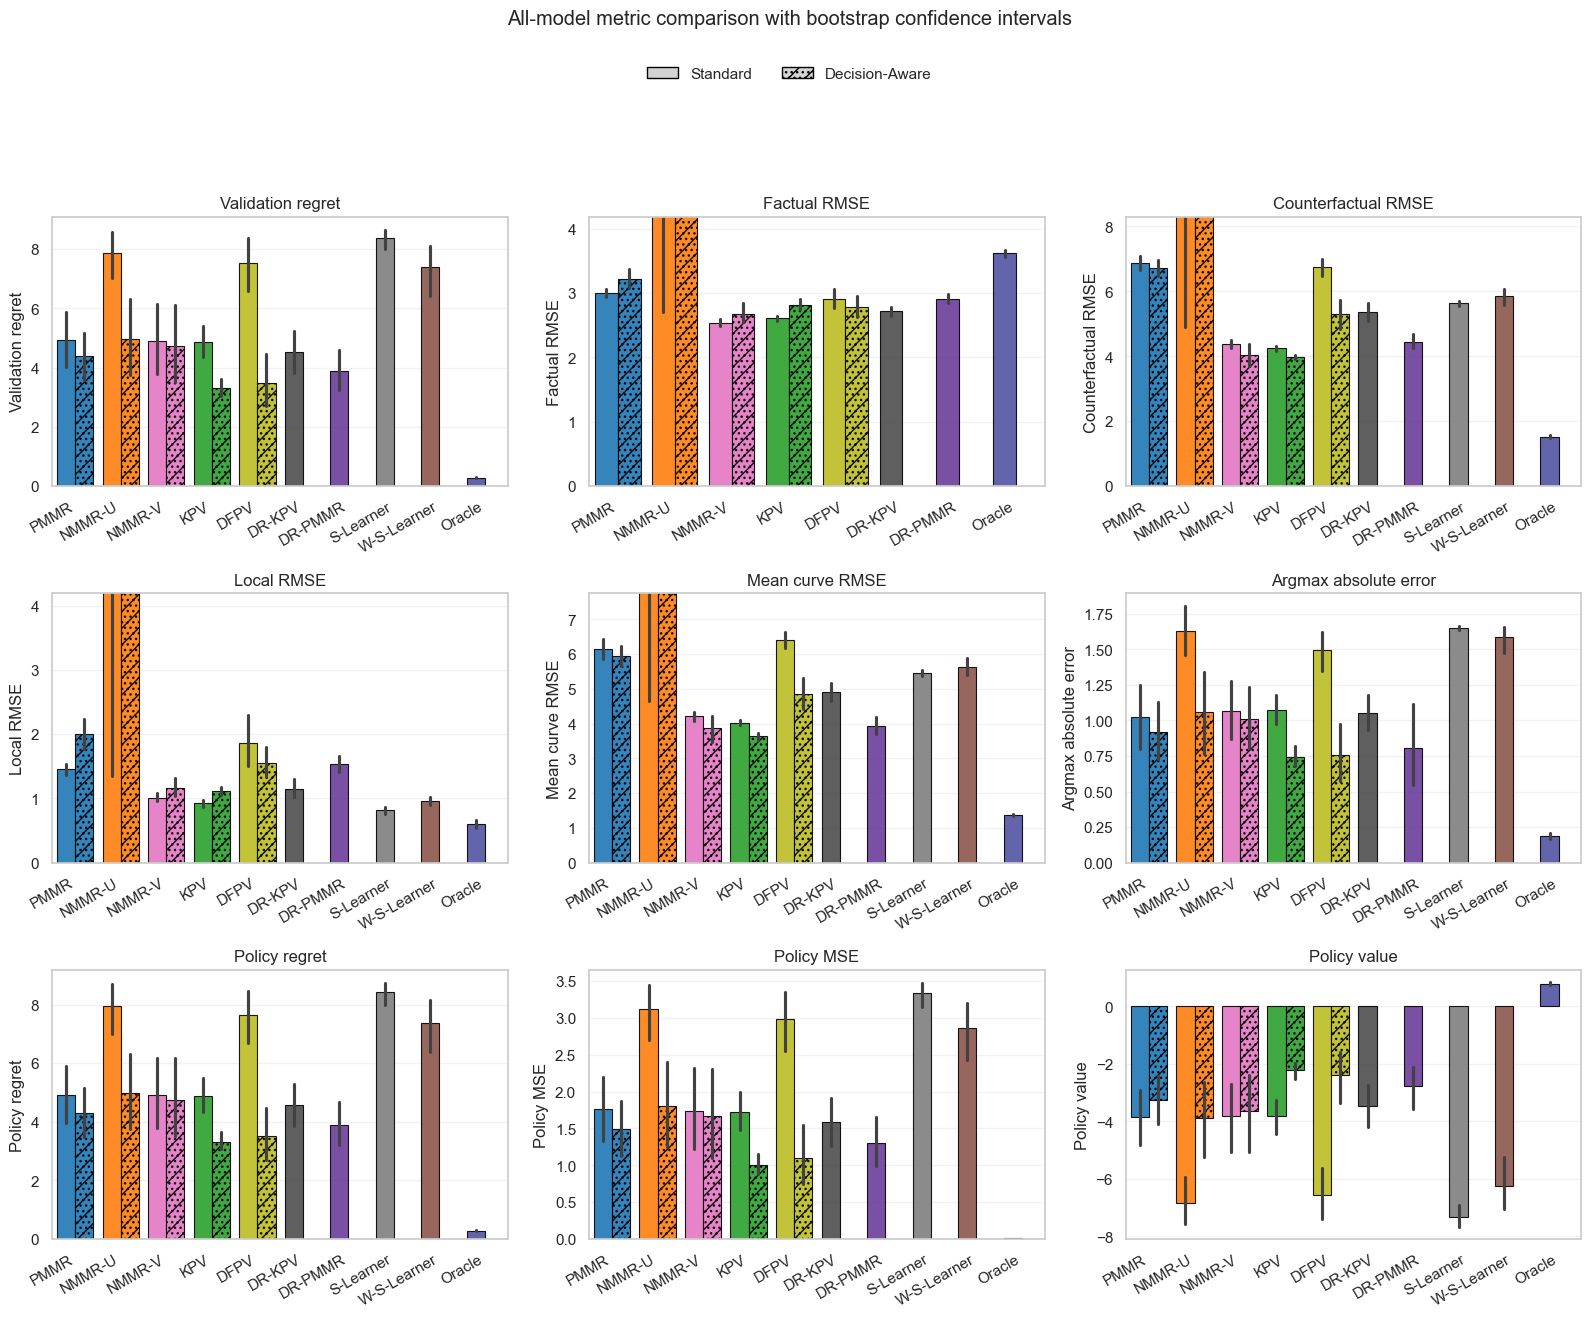

In [6]:
fig = plot_method_metrics_ci_grid_da_grouped(
    metrics_df,
    summary_df,
    metrics_to_use,
    metric_labels=METRIC_LABELS,
    ncols=3,
    pattern_map=DA_PATTERN_MAP,
    confidence=CONFIDENCE,
    title="All-model metric comparison with bootstrap confidence intervals",
)
save_figure(fig, ANALYSIS_DIR / "all_model_metrics_ci_grid.png")
save_figure(fig, ANALYSIS_DIR / "all_model_metrics_ci_grid.pdf")
plt.show()

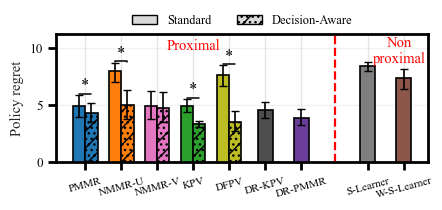

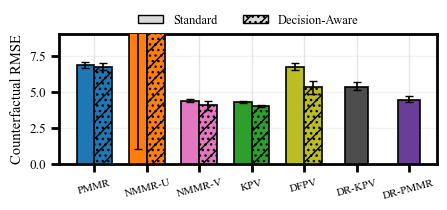

In [7]:
# Paper-style wider bar figures for policy regret and counterfactual RMSE
import numpy as np
from matplotlib.patches import Patch
from src.analysis.stats import wilcoxon_paired_by_label

NON_PROXIMAL_FAMILIES_BAR = {"S-Learner", "Naive OOSR"}
PAPER_BAR_METRICS = [
    ("regret_causal_marginal", "Policy regret", "paper_policy_regret_bar"),
    ("global_rmse", "Counterfactual RMSE", "paper_counterfactual_rmse_bar"),
]
PAPER_BAR_FIGSIZE = (4.6, 2.4)
PAPER_BAR_FONT_SIZE = 10.5
PAPER_BAR_N_BOOT = 3000
PAPER_BAR_LEGEND_LOC = "upper center"
PAPER_BAR_LEGEND_BBOX = (0.5, 1.24)
PAPER_BAR_GROUP_EXTRA_GAP = 0.85
PAPER_BAR_SEPARATOR_COLOR = "red"
PAPER_BAR_SIG_ENABLE = True
PAPER_BAR_SIG_DISABLE_METRICS = {"global_rmse"}
PAPER_BAR_SIG_P = 0.05
PAPER_BAR_SIG_USE_HOLM = True
PAPER_BAR_SOLO_WIDTH_MULT = 1.24
PAPER_BAR_WIDTH = 0.34
PAPER_BAR_RMSE_EXCLUDE_FAMILIES = ["NMMR-U", "Weighted NMMR-U"]
PAPER_BAR_HIDE_FAMILIES_BY_METRIC = {
    "regret_causal_marginal": ["Oracle S-Learner", "Oracle Naive OOSR"],
    "global_rmse": ["S-Learner", "Naive OOSR", "Oracle S-Learner", "Oracle Naive OOSR"],
}
PAPER_BAR_FAMILY_ANNOTATIONS = {
    "proximal": "Proximal",
    "non_proximal": "Non\nproximal",
}

METHOD_COLORS.update({
    "DR-KPV": "#4d4d4d",
    "DR-PMMR conditional": "#6a3d9a",
    "DR-PMMR marginal": "#b15928",
})


def _paper_bar_bootstrap_ci(values: np.ndarray, n_boot: int, seed: int = 13, alpha: float = 0.05):
    arr = np.asarray(values, dtype=float)
    if arr.size == 0:
        return np.nan, np.nan
    if arr.size == 1:
        return float(arr[0]), float(arr[0])
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, arr.size, size=(int(n_boot), arr.size))
    means = arr[idx].mean(axis=1)
    low = float(np.quantile(means, alpha / 2.0))
    high = float(np.quantile(means, 1.0 - alpha / 2.0))
    return low, high


def _paper_paired_family_values_for_metric(metric_name: str):
    source_rows = summary_df.loc[
        summary_df["metric"].astype(str) == str(metric_name),
        ["source_split", "source_metric"],
    ].drop_duplicates()
    if source_rows.empty:
        return {}
    split_name = str(source_rows.iloc[0]["source_split"])
    source_metric = str(source_rows.iloc[0]["source_metric"])
    if source_metric not in metrics_df.columns:
        return {}

    frame = metrics_df.copy()
    if "split" in frame.columns:
        frame = frame[frame["split"].astype(str) == split_name]
    if frame.empty:
        return {}

    frame = frame[[col for col in ["method", "dataset", "seed", "split", source_metric] if col in frame.columns]].copy()
    frame["value"] = pd.to_numeric(frame[source_metric], errors="coerce")
    frame = frame[frame["value"].notna()].copy()
    if frame.empty:
        return {}

    family_mode = frame["method"].astype(str).map(_split_family_mode)
    frame["family"] = [family for family, _ in family_mode]
    frame["mode"] = [mode for _, mode in family_mode]

    paired = {}
    for family in sorted(frame["family"].astype(str).unique()):
        fam = frame[frame["family"].astype(str) == family].copy()
        std = fam[fam["mode"].astype(str) == "standard"].copy()
        da = fam[fam["mode"].astype(str) == "DA"].copy()
        if std.empty or da.empty:
            continue

        keys = [k for k in ["dataset", "seed", "split"] if (k in std.columns and k in da.columns)]
        if keys:
            merged = std[keys + ["value"]].rename(columns={"value": "standard"}).merge(
                da[keys + ["value"]].rename(columns={"value": "DA"}),
                on=keys,
                how="inner",
            )
            da_vals = pd.to_numeric(merged["DA"], errors="coerce").to_numpy(dtype=float)
            std_vals = pd.to_numeric(merged["standard"], errors="coerce").to_numpy(dtype=float)
        else:
            da_vals = pd.to_numeric(da["value"], errors="coerce").to_numpy(dtype=float)
            std_vals = pd.to_numeric(std["value"], errors="coerce").to_numpy(dtype=float)
            n = int(min(da_vals.size, std_vals.size))
            da_vals = da_vals[:n]
            std_vals = std_vals[:n]

        mask = np.isfinite(da_vals) & np.isfinite(std_vals)
        da_vals = da_vals[mask]
        std_vals = std_vals[mask]
        if da_vals.size > 0:
            paired[family] = (da_vals, std_vals)
    return paired


def _plot_paper_metric_bar(metric_name: str, ylabel: str, save_stem: str):
    plot_df_single = _build_metric_plot_df(metrics_df, summary_df, [metric_name])
    metric_df = plot_df_single[plot_df_single["metric"].astype(str) == str(metric_name)].copy()
    hide_families = PAPER_BAR_HIDE_FAMILIES_BY_METRIC.get(str(metric_name), [])
    if hide_families:
        metric_df = metric_df[~metric_df["family"].astype(str).isin(set(hide_families))].copy()
    if metric_df.empty:
        raise ValueError(f"No data found for metric {metric_name!r}.")

    family_order = _ordered_families_from_methods(metric_df["family"].dropna().unique())
    proximal_families = [f for f in family_order if str(f) not in NON_PROXIMAL_FAMILIES_BAR]
    non_proximal_families = [f for f in family_order if str(f) in NON_PROXIMAL_FAMILIES_BAR]
    family_order = proximal_families + non_proximal_families
    color_map = _family_color_map(family_order)
    mode_order = ["standard", "DA"]
    mode_label_map = {"standard": "Standard", "DA": "Decision-Aware"}

    family_centers = np.arange(len(family_order), dtype=float)
    if proximal_families and non_proximal_families:
        split_idx = len(proximal_families)
        family_centers[split_idx:] += PAPER_BAR_GROUP_EXTRA_GAP


    fig, ax = plt.subplots(figsize=PAPER_BAR_FIGSIZE)
    plt.rcParams.update({
        "font.family": "serif",
        "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
        "text.color": "black",
        "axes.labelcolor": "black",
        "axes.edgecolor": "black",
        "axes.titlecolor": "black",
        "xtick.color": "black",
        "ytick.color": "black",
        "legend.labelcolor": "black",
    })

    xtick_labels = []
    top_y = []
    sig_enabled = PAPER_BAR_SIG_ENABLE and str(metric_name) not in PAPER_BAR_SIG_DISABLE_METRICS
    paired = _paper_paired_family_values_for_metric(metric_name) if sig_enabled else {}

    for center, family in zip(family_centers, family_order, strict=False):
        fam = metric_df[metric_df["family"].astype(str) == str(family)].copy()
        present_modes = [mode for mode in mode_order if mode in set(fam["mode"].astype(str))]
        if len(present_modes) == 2:
            offsets = {
                "standard": -PAPER_BAR_WIDTH / 2.0,
                "DA": PAPER_BAR_WIDTH / 2.0,
            }
            widths = {mode: PAPER_BAR_WIDTH for mode in present_modes}
        else:
            offsets = {present_modes[0]: 0.0} if present_modes else {}
            widths = {present_modes[0]: PAPER_BAR_WIDTH * PAPER_BAR_SOLO_WIDTH_MULT} if present_modes else {}

        family_bar_tops = []
        for mode in present_modes:
            vals = pd.to_numeric(
                fam.loc[fam["mode"].astype(str) == mode, "value"],
                errors="coerce",
            ).dropna().to_numpy(dtype=float)
            if vals.size == 0:
                continue
            mean_val = float(np.mean(vals))
            low, high = _paper_bar_bootstrap_ci(vals, PAPER_BAR_N_BOOT, seed=13, alpha=1.0 - CONFIDENCE)
            err_low = max(0.0, mean_val - low)
            err_high = max(0.0, high - mean_val)
            xpos = center + offsets[mode]
            family_bar_tops.append(mean_val + err_high)
            ax.bar(
                xpos,
                mean_val,
                width=widths[mode],
                color=color_map.get(str(family), "tab:blue"),
                edgecolor="black",
                linewidth=1.2,
                hatch=(DA_PATTERN_MAP.get(mode) or ""),
                yerr=np.array([[err_low], [err_high]]),
                error_kw={"elinewidth": 1.2, "ecolor": "black", "capsize": 3},
                zorder=3,
            )
        xtick_labels.append(METHOD_LABELS.get(str(family), str(family)))
        top_y.append(max(family_bar_tops) if family_bar_tops else np.nan)

    ax.set_xticks(family_centers)
    ax.set_xticklabels(xtick_labels, rotation=15, ha="center", fontsize=PAPER_BAR_FONT_SIZE - 2.5, fontfamily="serif")
    ax.set_ylabel(ylabel, fontsize=PAPER_BAR_FONT_SIZE, fontfamily="serif")
    ax.tick_params(axis="both", which="major", direction="out", length=6, width=2, colors="black", bottom=True, left=True)
    ax.tick_params(axis="y", labelsize=PAPER_BAR_FONT_SIZE - 1)
    for tick in ax.get_yticklabels():
        tick.set_fontfamily("serif")
    for spine in ax.spines.values():
        spine.set_color("black")
        spine.set_linewidth(2)
        try:
            spine.set_joinstyle("round")
        except AttributeError:
            pass
    try:
        ax.patch.set_joinstyle("round")
    except AttributeError:
        pass
    ax.grid(axis="y", alpha=0.25, zorder=0)

    ymax = np.nanmax(top_y) if top_y and np.isfinite(np.nanmax(top_y)) else 1.0
    ylim_top = ymax * 1.28 if ymax > 0 else 1.0

    if str(metric_name).lower().endswith("rmse"):
        visible = metric_df.copy()
        visible = visible[~visible["family"].astype(str).isin(set(PAPER_BAR_RMSE_EXCLUDE_FAMILIES))]
        visible_vals = pd.to_numeric(visible["value"], errors="coerce")
        visible_vals = visible_vals[visible_vals.notna()]
        if not visible_vals.empty:
            ylim_top = max(ylim_top, float(visible_vals.max()) * (1.0 + RMSE_YMAX_MARGIN_RATIO))

    ax.set_ylim(0, ylim_top)

    if proximal_families and non_proximal_families:
        split_idx = len(proximal_families)
        separator_x = (family_centers[split_idx - 1] + family_centers[split_idx]) / 2.0
        ax.axvline(separator_x, color=PAPER_BAR_SEPARATOR_COLOR, linestyle="--", linewidth=1.6, zorder=2)
        ax.text(
            np.mean(family_centers[:split_idx]),
            ylim_top * 0.965,
            PAPER_BAR_FAMILY_ANNOTATIONS["proximal"],
            color=PAPER_BAR_SEPARATOR_COLOR,
            ha="center",
            va="top",
            fontsize=PAPER_BAR_FONT_SIZE,
        )
        ax.text(
            np.mean(family_centers[split_idx:]) + 0.35,
            ylim_top * 0.990,
            PAPER_BAR_FAMILY_ANNOTATIONS["non_proximal"],
            color=PAPER_BAR_SEPARATOR_COLOR,
            ha="center",
            va="top",
            fontsize=PAPER_BAR_FONT_SIZE,
        )

    if sig_enabled:
        tested = []
        for family in proximal_families:
            if family not in paired:
                continue
            da_vals, std_vals = paired[family]
            if da_vals.size == 0:
                continue
            tested.append((family, da_vals, std_vals))
        if tested:
            paired_values = {
                family: (da_vals, std_vals)
                for family, da_vals, std_vals in tested
            }
            test_results = wilcoxon_paired_by_label(
                paired_values,
                alternative="less",
                correction=("holm" if PAPER_BAR_SIG_USE_HOLM else "uncorrected"),
                zero_method="wilcox",
                alpha=PAPER_BAR_SIG_P,
            )
            sig_lookup = {
                str(label): bool(result.get("rejected", False))
                for label, result in test_results.items()
            }
            for family in proximal_families:
                if not sig_lookup.get(str(family), False):
                    continue
                if family not in paired:
                    continue
                fam = metric_df[metric_df["family"].astype(str) == str(family)].copy()
                present_modes = [mode for mode in mode_order if mode in set(fam["mode"].astype(str))]
                if set(present_modes) != {"standard", "DA"}:
                    continue
                center = family_centers[family_order.index(family)]
                left = center - PAPER_BAR_WIDTH / 2.0
                right = center + PAPER_BAR_WIDTH / 2.0
                base_y = top_y[family_order.index(family)]
                if not np.isfinite(base_y):
                    continue
                current_ymax = float(ax.get_ylim()[1])
                headroom = max(current_ymax - base_y, 0.0)
                if headroom <= 0:
                    continue
                gap = min(current_ymax * 0.008, headroom * 0.22)
                h = min(current_ymax * 0.002, headroom * 0.1)
                star_gap = min(current_ymax * 0.0005, headroom * 0.01)
                y0 = min(base_y + gap, current_ymax - h - star_gap - current_ymax * 0.012)
                if y0 <= base_y:
                    y0 = base_y + min(gap, headroom * 0.08)
                star_y = min(y0 + h + star_gap, current_ymax - current_ymax * 0.010)
                ax.plot([left, left, right, right], [y0, y0 + h, y0 + h, y0], color="black", linewidth=1.1)
                ax.text(center, star_y, "*", ha="center", va="bottom", fontsize=PAPER_BAR_FONT_SIZE + 1.5)

    legend_handles = [
        Patch(facecolor="#d9d9d9", edgecolor="black", label=mode_label_map["standard"]),
        Patch(facecolor="#d9d9d9", edgecolor="black", hatch=DA_PATTERN_MAP["DA"], label=mode_label_map["DA"]),
    ]
    ax.legend(
        handles=legend_handles,
        loc=PAPER_BAR_LEGEND_LOC,
        bbox_to_anchor=PAPER_BAR_LEGEND_BBOX,
        frameon=False,
        ncol=2,
        fontsize=PAPER_BAR_FONT_SIZE - 1.5,
    )

    fig.tight_layout()
    if metric_name == "Counterfactual RMSE" or save_stem == "paper_counterfactual_rmse_bar":
        plt.ylim(0,9)
    save_figure(fig, ANALYSIS_DIR / f"{save_stem}.png")
    save_figure(fig, ANALYSIS_DIR / f"{save_stem}.pdf")
    return fig


for metric_name, ylabel, save_stem in PAPER_BAR_METRICS:
    fig = _plot_paper_metric_bar(metric_name, ylabel, save_stem)
    if metric_name == "Counterfactual RMSE" or save_stem == "paper_counterfactual_rmse_bar":
        plt.ylim(0,9)
    plt.show()


## Aggregated Global Curves

This figure overlays the mean/global curves of every available model. Surface figures below remain DR-only.

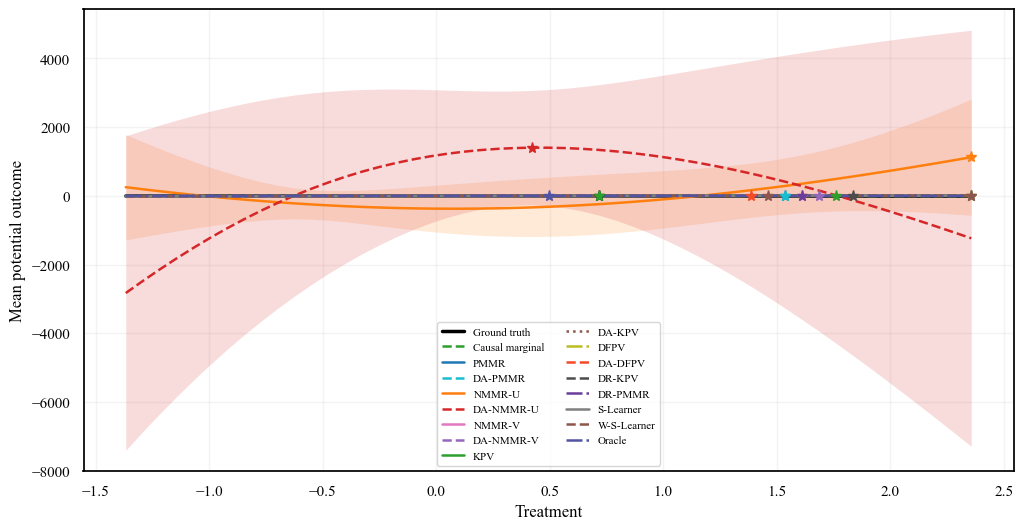

In [8]:
GLOBAL_METHODS = ordered_existing_methods(
    global_curves_df.loc[global_curves_df["curve_type"] == "prediction", "method"].unique()
)
GLOBAL_CURVE_PREDICTOR_TYPES = ("mean_or_primary",)
GLOBAL_CURVE_SEPARATE_PREDICTOR_TYPES = False
GLOBAL_REFERENCE_VISIBILITY = {
    "ground_truth_oracle_conditioned": True,
    "causal_marginal": True,
    "proxy_conditioned": False,
}
GLOBAL_MARK_CURVE_MAXIMA = True

fig = plot_global_curves(
    global_curves_df,
    methods=GLOBAL_METHODS,
    predictor_types=GLOBAL_CURVE_PREDICTOR_TYPES,
    separate_predictor_types=GLOBAL_CURVE_SEPARATE_PREDICTOR_TYPES,
    reference_visibility=GLOBAL_REFERENCE_VISIBILITY,
    mark_curve_maxima=GLOBAL_MARK_CURVE_MAXIMA,
    method_order=METHOD_ORDER,
    labels=METHOD_LABELS,
    colors=METHOD_COLORS,
    linestyles=METHOD_LINESTYLES,
    confidence=CONFIDENCE,
    show_ci=True,
    figsize=(12, 6),
)
save_figure(fig, ANALYSIS_DIR / "all_model_global_curves_ci.png")
save_figure(fig, ANALYSIS_DIR / "all_model_global_curves_ci.pdf")
plt.show()

## DR Patient-Specific Surfaces

Only DR methods are plotted in this section. The reference curves are still shown for interpretation, but no non-DR model surfaces are included.

surface seed: 1
patient ranks available for seed 1: 50
surface methods: ['DR-KPV', 'DR-PMMR conditional']


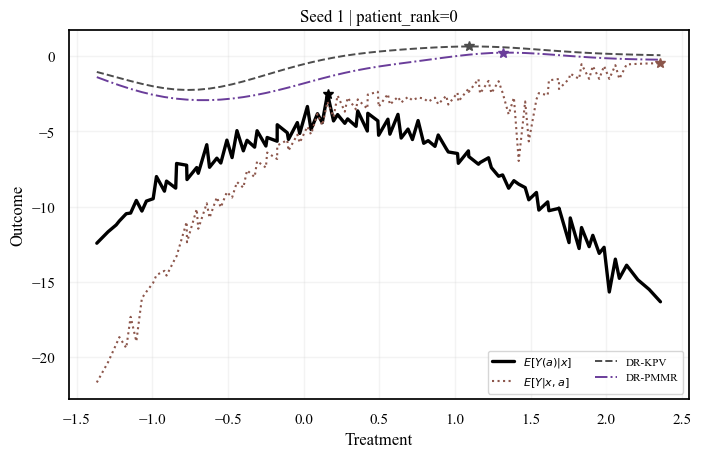

In [9]:
if not dr_surface_methods:
    raise ValueError("No DR methods were found in patient_curves.csv")
if not dr_surface_seeds:
    raise ValueError("No DR prediction rows were found in patient_curves.csv")

SURFACE_SEED = int(dr_surface_seeds[0])
dr_seed_rows = dr_prediction_rows[dr_prediction_rows["seed"].astype(int) == SURFACE_SEED].copy()
seed_patient_ranks = sorted(dr_seed_rows["patient_rank"].dropna().astype(int).unique().tolist())
if not seed_patient_ranks:
    raise ValueError(f"No DR patient ranks found for seed {SURFACE_SEED}")
PATIENT_RANK = int(seed_patient_ranks[0])
SURFACE_METHODS = ordered_existing_methods(dr_seed_rows["method"].dropna().unique())
SURFACE_REFERENCE_VISIBILITY = {
    "ground_truth_causal": True,
    "associational": True,
    "proxy_conditioned": False,
    "oracle_conditioned": False,
}
SURFACE_MARK_CURVE_MAXIMA = True

print(f"surface seed: {SURFACE_SEED}")
print(f"patient ranks available for seed {SURFACE_SEED}: {len(seed_patient_ranks)}")
print(f"surface methods: {SURFACE_METHODS}")

fig = plot_patient_surface_from_table(
    patient_curves_df,
    seed=SURFACE_SEED,
    patient_rank=PATIENT_RANK,
    methods=SURFACE_METHODS,
    reference_visibility=SURFACE_REFERENCE_VISIBILITY,
    labels=METHOD_LABELS,
    colors=METHOD_COLORS,
    linestyles=METHOD_LINESTYLES,
    mark_curve_maxima=SURFACE_MARK_CURVE_MAXIMA,
    figsize=(8, 4.8),
)
save_figure(fig, ANALYSIS_DIR / f"dr_patient_surface_seed_{SURFACE_SEED}_rank_{PATIENT_RANK}.png")
save_figure(fig, ANALYSIS_DIR / f"dr_patient_surface_seed_{SURFACE_SEED}_rank_{PATIENT_RANK}.pdf")
plt.show()

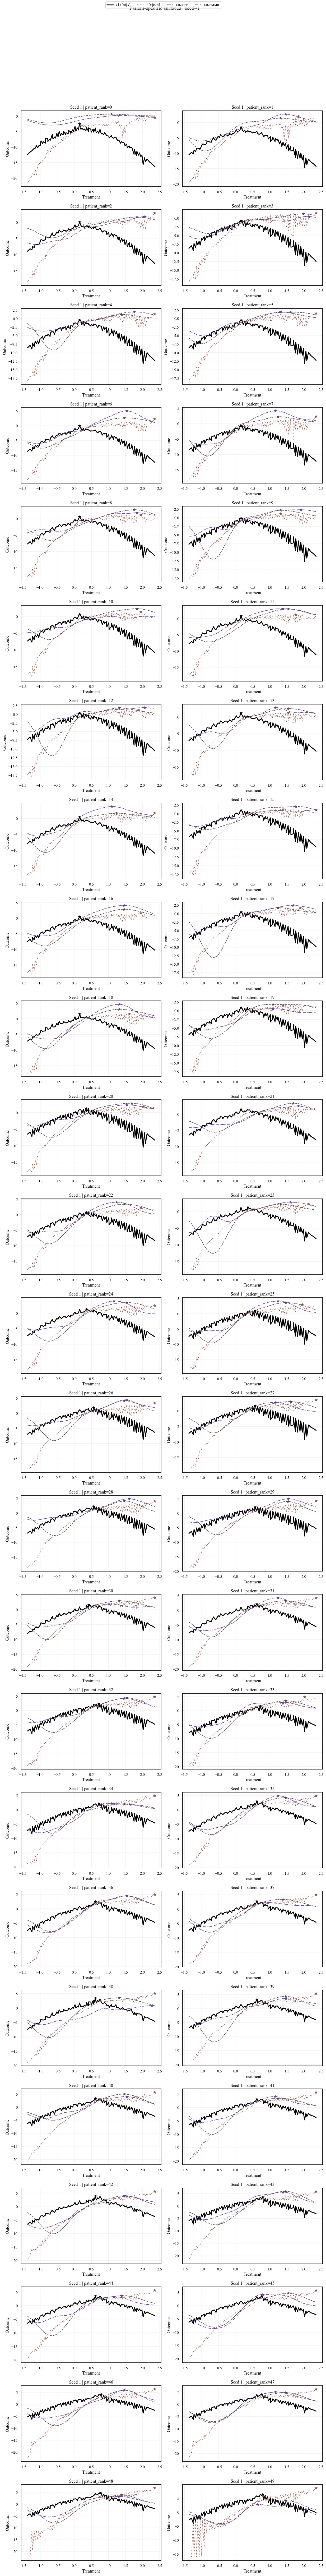

In [10]:
GALLERY_RANKS = seed_patient_ranks

fig = plot_patient_surface_gallery_from_table(
    patient_curves_df,
    seed=SURFACE_SEED,
    patient_ranks=GALLERY_RANKS,
    methods=SURFACE_METHODS,
    reference_visibility=SURFACE_REFERENCE_VISIBILITY,
    labels=METHOD_LABELS,
    colors=METHOD_COLORS,
    linestyles=METHOD_LINESTYLES,
    mark_curve_maxima=SURFACE_MARK_CURVE_MAXIMA,
    ncols=2,
    figsize_per_panel=(6.2, 3.9),
)
save_figure(fig, ANALYSIS_DIR / f"dr_patient_surface_gallery_seed_{SURFACE_SEED}.png")
save_figure(fig, ANALYSIS_DIR / f"dr_patient_surface_gallery_seed_{SURFACE_SEED}.pdf")
plt.show()

## Non-Parametric Statistical Tests

Oracle methods are excluded from the tests, matching the usual comparison setup.

In [11]:
TEST_METHODS = non_oracle_methods(available_methods)
tests = run_statistical_tests(
    metrics_df,
    metrics_to_use,
    split=DEFAULT_SPLIT,
    methods=TEST_METHODS,
    metric_directions=METRIC_DIRECTIONS,
    alpha=ALPHA,
)

friedman_posthoc_table = statistical_test_table(tests["friedman_posthoc"], alpha=ALPHA, methods=TEST_METHODS)
wilcoxon_table = statistical_test_table(tests["wilcoxon"], alpha=ALPHA, methods=TEST_METHODS)

display(tests["friedman_omnibus"])
display(friedman_posthoc_table)
display(wilcoxon_table)

export_analysis_tables(
    ANALYSIS_DIR,
    tests=tests,
    test_methods=TEST_METHODS,
)

,metric,n_blocks,n_methods,baseline,higher_is_better,friedman_statistic,friedman_p_value
0,val_regret,10,14,Weighted KPV,False,71.162560,4.900299e-10
1,factual_mean_rmse,10,12,NMMR-V,False,62.692308,2.919551e-09
2,global_rmse,10,14,Weighted KPV,False,89.874286,1.477085e-13
3,local_rmse,10,14,S-Learner,False,88.114286,3.202513e-13
4,mean_curve_rmse,10,14,Weighted KPV,False,86.754286,5.815346e-13
5,mean_curve_argmax_abs_error,10,14,Weighted KPV,False,67.349541,2.459564e-09
6,regret_causal_marginal,10,14,Weighted KPV,False,70.024417,7.944328e-10
7,policy_mse_causal_marginal,10,14,Weighted KPV,False,70.619226,6.172588e-10
8,policy_value_causal_marginal,10,14,Weighted KPV,True,70.487681,6.527054e-10


method,PMMR,Weighted PMMR,NMMR-U,Weighted NMMR-U,NMMR-V,Weighted NMMR-V,KPV,Weighted KPV,DFPV,Weighted DFPV,DR-KPV,DR-PMMR conditional,S-Learner,Naive OOSR
metric,,,,,,,,,,,,,,
factual_mean_rmse,<1e-3,<1e-3,0.002,<1e-3,1.000* (baseline),0.321*,0.477*,0.002,0.006,0.012,0.062*,<1e-3,NaN,NaN
global_rmse,<1e-3,<1e-3,0.002,<1e-3,0.389*,0.929*,0.929*,1.000* (baseline),<1e-3,0.007,0.002,0.389*,0.001,<1e-3
local_rmse,<1e-3,<1e-3,<1e-3,<1e-3,0.349*,0.053*,1.000*,0.062*,<1e-3,<1e-3,0.062*,<1e-3,1.000* (baseline),0.785*
mean_curve_argmax_abs_error,0.544*,0.958*,<1e-3,0.380*,0.462*,0.544*,0.544*,1.000* (baseline),0.004,1.000*,0.265*,1.000*,<1e-3,<1e-3
mean_curve_rmse,<1e-3,<1e-3,0.002,<1e-3,0.240*,0.855*,0.726*,1.000* (baseline),<1e-3,0.012,0.009,0.855*,<1e-3,<1e-3
policy_mse_causal_marginal,0.293*,0.726*,<1e-3,0.120*,0.293*,0.412*,0.293*,1.000* (baseline),<1e-3,1.000*,0.293*,0.855*,<1e-3,<1e-3
policy_value_causal_marginal,0.293*,0.658*,<1e-3,0.103*,0.293*,0.367*,0.293*,1.000* (baseline),<1e-3,1.000*,0.293*,0.929*,<1e-3,<1e-3
regret_causal_marginal,0.334*,0.798*,<1e-3,0.162*,0.334*,0.412*,0.334*,1.000* (baseline),<1e-3,1.000*,0.334*,1.000*,<1e-3,<1e-3
val_regret,0.297*,0.798*,<1e-3,0.139*,0.274*,0.515*,0.297*,1.000* (baseline),<1e-3,1.000*,0.368*,0.929*,<1e-3,<1e-3


method,PMMR,Weighted PMMR,NMMR-U,Weighted NMMR-U,NMMR-V,Weighted NMMR-V,KPV,Weighted KPV,DFPV,Weighted DFPV,DR-KPV,DR-PMMR conditional,S-Learner,Naive OOSR
metric,,,,,,,,,,,,,,
factual_mean_rmse,0.012,0.012,0.012,0.012,1.000* (baseline),0.012,0.012,0.012,0.012,0.012,0.012,0.012,NaN,NaN
global_rmse,0.014,0.014,0.014,0.015,0.014,0.492*,0.014,1.000* (baseline),0.014,0.014,0.014,0.014,0.014,0.014
local_rmse,0.014,0.014,0.014,0.014,0.014,0.014,0.049,0.014,0.014,0.014,0.014,0.014,1.000* (baseline),0.014
mean_curve_argmax_abs_error,0.191*,0.258*,0.014,0.195*,0.020,0.191*,0.014,1.000* (baseline),0.020,1.000*,0.031,1.000*,0.014,0.014
mean_curve_rmse,0.014,0.014,0.014,0.014,0.014,0.131*,0.014,1.000* (baseline),0.014,0.014,0.014,0.097*,0.014,0.014
policy_mse_causal_marginal,0.078*,0.168*,0.014,0.111*,0.044,0.161*,0.014,1.000* (baseline),0.014,0.846*,0.078*,0.168*,0.014,0.014
policy_value_causal_marginal,0.096*,0.193*,0.014,0.193*,0.044,0.193*,0.014,1.000* (baseline),0.014,0.846*,0.078*,0.290*,0.014,0.014
regret_causal_marginal,0.130*,0.193*,0.014,0.193*,0.044,0.193*,0.014,1.000* (baseline),0.014,0.846*,0.078*,0.290*,0.014,0.014
val_regret,0.096*,0.161*,0.014,0.146*,0.044,0.168*,0.014,1.000* (baseline),0.014,0.846*,0.078*,0.196*,0.014,0.014


{'friedman_omnibus': WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr/results/wu2024_article/analysis/07_doubly_robust_results/all_seeds/friedman_omnibus.csv'),
 'friedman_posthoc': WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr/results/wu2024_article/analysis/07_doubly_robust_results/all_seeds/friedman_posthoc.csv'),
 'wilcoxon': WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr/results/wu2024_article/analysis/07_doubly_robust_results/all_seeds/wilcoxon.csv'),
 'friedman_posthoc_holm_table': WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr/results/wu2024_article/analysis/07_doubly_robust_results/all_seeds/friedman_posthoc_holm_table.csv'),
 'wilcoxon_holm_table': WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr/results/wu2024_article/analysis/07_doubly_robust_results/all_s